# Learning to generate numbers with a GAN
### DRP: generative adversarial networks

In the previous lesson, a network learned a function: an input $x$ had a target $\sin(x)$. Here, we learn to **generate new samples from a distribution**. A generated sample has no paired correct answer.

Our example uses a bell-shaped distribution with mean 2 and standard deviation 0.5. We can create the data ourselves, so we do not need images, downloads, or a GPU. We already know how to sample this distribution directly; the GAN is a small teaching example, not a better way to sample a known normal distribution.

The sequence is **data → two networks → two losses → alternating training → generation and evaluation**. We will use a **generator** $G$ to transform random noise into candidate samples and a **discriminator** to distinguish training examples from generated samples.

Run the cells in order. Restart the kernel and run all cells before changing an experiment. The saved outputs and the four plots in `figures/` come from an executed run. Install `torch`, `matplotlib`, and `ipykernel` as described in `README.txt`. Fixed seeds help reproduce the run in the same environment; other versions or platforms can give different results.

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from pathlib import Path

torch.manual_seed(7)
torch.set_num_threads(1)
Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 12})

## 1. Create the training data

We make 2,048 independent draws from $X\sim\mathcal N(2,0.5^2)$ by sampling $\varepsilon\sim\mathcal N(0,1)$ and setting $X=2+0.5\varepsilon$. The second parameter in $\mathcal N(2,0.5^2)$ is the **variance**; 0.5 is the standard deviation.

The data have shape `(2048, 1)`: one real number per example. During training, the discriminator will receive batches of these examples. It does not receive the normal density formula, its mean, or its standard deviation as inputs.

In [2]:
x_train = 2 + 0.5 * torch.randn(2048, 1)

A density histogram describes how the samples are distributed. Its total area is 1; the bar heights are densities, not individual probabilities.

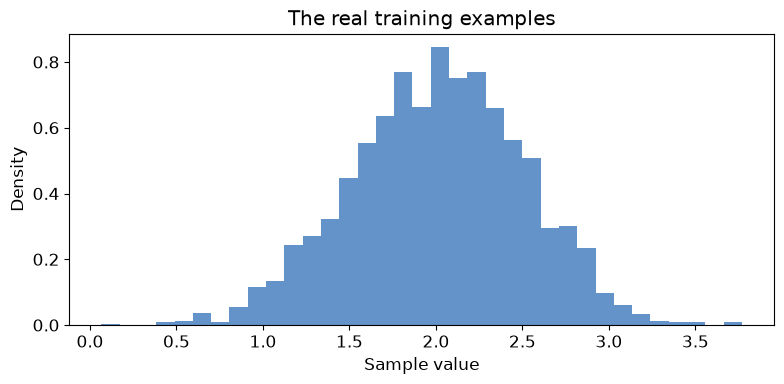

In [3]:
plt.hist(x_train[:, 0], bins=35, density=True, color="#2266B3", alpha=0.7)
plt.xlabel("Sample value")
plt.ylabel("Density")
plt.title("The real training examples")
plt.tight_layout()
plt.savefig("figures/training_data.pdf")
plt.show()

## 2. Define the generator and discriminator

The generator receives random **latent noise** $z\sim\mathcal N(0,1)$ and produces a number $G_\theta(z)$. Different noise draws can produce different samples. With fixed parameters and the same $z$, this generator always returns the same value.

Both networks have one input, 16 hidden neurons with `Tanh`, and one output. Each has **49 parameters**: $(1\cdot16+16)+(16\cdot1+1)$. There are **98 parameters in total**, in two separate sets. Even though their architectures match, their roles, parameters, and losses differ.

The discriminator module `D` returns a real-valued **logit** $s_\phi(x)$. For interpretation, $d_\phi(x)=\operatorname{sigmoid}(s_\phi(x))$ is its estimated probability that the input is real under the equal-prior real/fake classification task. Training uses the logit directly. We do **not** add a sigmoid layer because `BCEWithLogitsLoss` includes that operation internally.

In [4]:
G = nn.Sequential(
    nn.Linear(1, 16),
    nn.Tanh(),
    nn.Linear(16, 1)
)
D = nn.Sequential(
    nn.Linear(1, 16),
    nn.Tanh(),
    nn.Linear(16, 1)
)

We save outputs from the untrained generator for a visual comparison later. This noise is only for visualization; it is not a batch used for parameter updates.

In [5]:
z_visual = torch.randn(2048, 1)
with torch.no_grad():
    before = G(z_visual)

## 3. Define the two losses

For a logit $s$ and a label $t\in\{0,1\}$, binary cross-entropy is

$$\ell(s,t)=-t\log\sigma(s)-(1-t)\log(1-\sigma(s)).$$

For **discriminator training**, real examples have label 1 and generated examples have label 0:

$$L_D=\frac{1}{m}\sum_i\ell(s_\phi(x_i),1)
+\frac{1}{m}\sum_i\ell(s_\phi(G_\theta(z_i)),0).$$

For **generator training**, we use label 1 for generated samples:

$$L_G=\frac{1}{m}\sum_i\ell(s_\phi(G_\theta(z_i)),1)
=-\frac{1}{m}\sum_i\log d_\phi(G_\theta(z_i)).$$

This label tells the optimizer what the generator wants the discriminator to predict; it does not turn generated samples into real training data. This is the **non-saturating generator loss**, rather than the original minimax generator loss. It provides a useful learning signal when the discriminator confidently rejects generated samples.

We use **Adam** with learning rate 0.001. Adam uses running averages of gradients and squared gradients to scale updates. Its `betas` control these averages. The two optimizers manage different parameter sets. Unlike the previous lesson, one fixed loss is not being minimized by both networks.

In [6]:
bce = nn.BCEWithLogitsLoss()
opt_g = torch.optim.Adam(G.parameters(), lr=0.001, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(D.parameters(), lr=0.001, betas=(0.5, 0.999))

## 4. Alternate discriminator and generator updates

Each iteration has two updates, with a batch size of 128:

1. **Update the discriminator.** Sample real examples from the fixed training set and generate a fake batch. Use labels 1 and 0. `fake.detach()` prevents this backward pass from entering the generator.
2. **Update the generator.** Draw fresh noise and ask the discriminator to give the generated samples label 1. Only `opt_g.step()` updates parameters in this step.

`D.requires_grad_(False)` freezes the discriminator's parameters during the generator step. PyTorch still differentiates the discriminator's output with respect to its **input**, so the gradient can reach the generator. The next iteration restores discriminator parameter gradients with `True`. Do not use `no_grad()` around the generator's training calculation: that would remove the graph it needs.

For one generated example, the chain rule gives

$$\nabla_\theta\ell(s_\phi(G_\theta(z)),1)
=(d_\phi(G_\theta(z))-1)
\left.\frac{\partial s_\phi(x)}{\partial x}\right|_{x=G_\theta(z)}
\nabla_\theta G_\theta(z).$$

The discriminator therefore supplies a direction for changing generated values. We use 6,000 **iterations**, not 6,000 full passes through the data: real examples are sampled with replacement each time. The test samples are created only after training is complete.

In [7]:
d_history, g_history = [], []
for step in range(6000):
    real = x_train[torch.randint(len(x_train), (128,))]
    fake = G(torch.randn(128, 1))

    D.requires_grad_(True)
    opt_d.zero_grad()
    d_loss = bce(D(real), torch.ones(128, 1))
    d_loss = d_loss + bce(D(fake.detach()), torch.zeros(128, 1))
    d_loss.backward()
    opt_d.step()

    D.requires_grad_(False)
    opt_g.zero_grad()
    fake = G(torch.randn(128, 1))
    g_loss = bce(D(fake), torch.ones(128, 1))
    g_loss.backward()
    opt_g.step()

    d_history.append(d_loss.item())
    g_history.append(g_loss.item())

### Reading GAN losses

GAN losses can oscillate because each network changes the other network's task. They do not have to decrease together. With our scaling, an ideal discriminator output of $1/2$ gives $L_D=2\log 2\approx1.386$ and $L_G=\log 2\approx0.693$.

These values are **reference levels, not stopping rules or proof of success**. A weak discriminator can output $1/2$ even for poor samples. We must inspect the generated distribution too. The losses below come from different batches and update stages within each iteration.

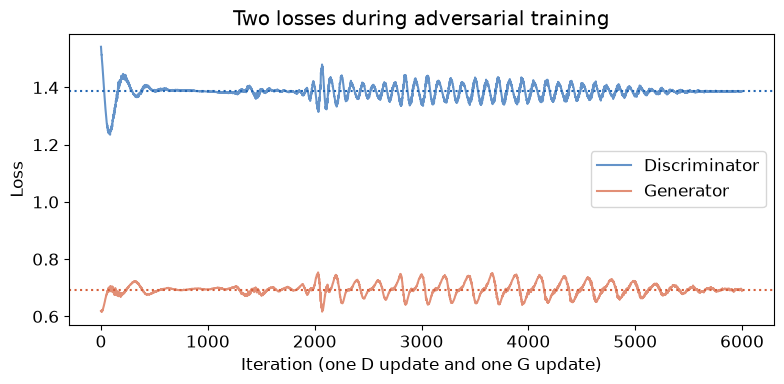

In [8]:
plt.plot(d_history, color="#2266B3", alpha=0.7, label="Discriminator")
plt.plot(g_history, color="#D6603C", alpha=0.7, label="Generator")
plt.axhline(2 * torch.log(torch.tensor(2.)).item(), color="#2266B3", linestyle=":")
plt.axhline(torch.log(torch.tensor(2.)).item(), color="#D6603C", linestyle=":")
plt.xlabel("Iteration (one D update and one G update)")
plt.ylabel("Loss")
plt.title("Two losses during adversarial training")
plt.legend()
plt.tight_layout()
plt.savefig("figures/loss_curve.pdf")
plt.show()

## 5. Generate new samples and evaluate

After training, **only the generator is needed for generation**. We draw 5,000 new noise inputs and a separate set of 5,000 real test samples. The test seed is different from the training seed. These real test samples and latent inputs were not used for training.

Evaluation compares distributions, not pairs of samples: there is no required match between the first generated number and the first real test number. We use the final checkpoint after the preset 6,000 iterations. If you use these test results to choose a model or training duration, reserve a fresh test set for the final evaluation.

In [9]:
torch.manual_seed(2026)
G.eval()
with torch.no_grad():
    real_test = 2 + 0.5 * torch.randn(5000, 1)
    generated = G(torch.randn(5000, 1))
print("Ten newly generated values:")
print(generated[:10, 0])

Ten newly generated values:
tensor([2.6636, 2.4900, 1.0034, 2.4647, 1.3316, 2.0428, 1.7904, 2.4453, 1.1390,
        1.7406])


We compare normalized histograms. The first panel shows the untrained generator against training data; the second uses fresh real and generated samples after training. Each panel has its own density scale so both comparisons remain readable.

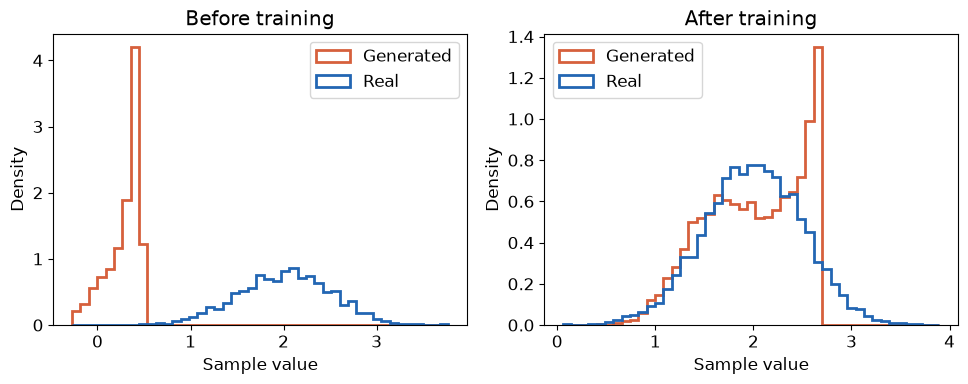

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist([x_train[:, 0], before[:, 0]], bins=45, density=True,
             histtype="step", linewidth=2, color=["#2266B3", "#D6603C"],
             label=["Real", "Generated"])
axes[1].hist([real_test[:, 0], generated[:, 0]], bins=45, density=True,
             histtype="step", linewidth=2, color=["#2266B3", "#D6603C"],
             label=["Real", "Generated"])
for ax, title in zip(axes, ["Before training", "After training"]):
    ax.set(xlabel="Sample value", ylabel="Density", title=title)
    ax.legend()
fig.tight_layout()
fig.savefig("figures/generated_distribution.pdf")
plt.show()

### Numerical checks

We compare the mean, standard deviation, and the 10th, 50th, and 90th percentiles. The 50th percentile is the median. For example, approximately 10% of samples lie below the 10th percentile.

The normal distribution has theoretical mean 2 and standard deviation 0.5. Its 10th and 90th percentiles are about 1.359 and 2.641. Finite samples need not match these values exactly. `std(unbiased=False)` uses the sample count in the denominator to summarize the observed spread.

Agreement in mean and standard deviation alone does not establish that two distributions match. Quantiles and the next plot inspect more of their shapes, but still do not certify perfect generation.

In [11]:
print("Sample        Mean      Std       Q10       Q50       Q90")
for name, values in [("Real test", real_test), ("Generated", generated)]:
    q = torch.quantile(values, torch.tensor([0.1, 0.5, 0.9]))
    print(f"{name:10s} {values.mean():9.5f} {values.std(unbiased=False):9.5f}"
          f" {q[0]:9.5f} {q[1]:9.5f} {q[2]:9.5f}")

Sample        Mean      Std       Q10       Q50       Q90
Real test    1.99510   0.50366   1.34386   2.00074   2.62757
Generated    2.00007   0.49586   1.31459   2.02866   2.63094


The quantile plot puts real-sample quantiles on the horizontal axis and generated-sample quantiles on the vertical axis, from the 1st to the 99th percentile. Points near the diagonal mean the corresponding quantiles are similar. Departures near the ends reveal differences in the tails.

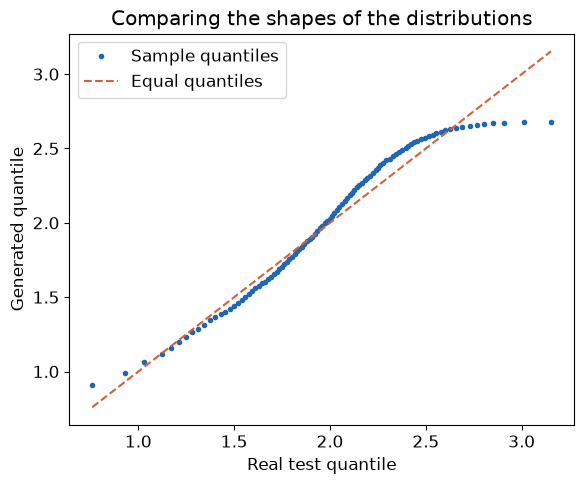

In [12]:
levels = torch.linspace(0.01, 0.99, 99)
real_q = torch.quantile(real_test, levels)
fake_q = torch.quantile(generated, levels)
plt.figure(figsize=(6, 5))
plt.plot(real_q, fake_q, ".", color="#2266B3", label="Sample quantiles")
plt.plot(real_q, real_q, "--", color="#D6603C", label="Equal quantiles")
plt.xlabel("Real test quantile")
plt.ylabel("Generated quantile")
plt.title("Comparing the shapes of the distributions")
plt.legend()
plt.tight_layout()
plt.savefig("figures/quantile_comparison.pdf")
plt.show()

## What did the GAN learn?

The generator learned a transformation of noise whose outputs approximately resemble the real examples. It did not receive a target number for each latent input. The discriminator learned a classification task, and the generator learned through that classifier's derivatives.

This small experiment is not a guarantee of convergence. A generator can produce too little variety (**mode collapse**), miss tails, or oscillate during training. In fact, a finite weighted sum of `Tanh` outputs is bounded, whereas a normal distribution has unbounded support. This architecture can only approximate the normal distribution over the region represented well by the data.

**Reading the saved run:** the mean and standard deviation are close to their targets, but the histogram has excess generated mass near 2.7, and the upper end of the quantile plot flattens. The model has learned the broad location and spread, while its shape and upper tail still differ. This is a useful example of why good summary statistics and near-reference losses do not establish successful distribution matching.

We generate independent scalar samples, **not a time series**. A sequence of independent draws does not reproduce temporal dependence. Later in the project, a generator can output a vector $(X_{t_1},\ldots,X_{t_T})$, and evaluation must examine the dependence between times. We plan to investigate how Volterra signatures can contribute to that task; this notebook does not implement them.

## Experiments for students

1. Change the seed to 8. Does the same training schedule give a similar distribution?
2. Train for 1,000 iterations instead of 6,000. Do near-reference losses guarantee a good histogram?
3. Use 4 hidden neurons in both layers of each network. How does the spread change?
4. Change the real distribution's mean or standard deviation in **both** the training and test data cells.
5. As an optional challenge, use a mixture of two separated normal distributions. Can the generator cover both peaks? A single good run on one normal distribution does not guarantee this harder task will work.

Restart and run all cells for each experiment. Compare distributions and report failed runs as well as successful ones. If you repeatedly inspect the test results, treat them as validation and use new samples for your final test.

**References**

- Goodfellow et al. (2014), [Generative Adversarial Nets](https://arxiv.org/abs/1406.2661), especially Section 3 for alternating training and the non-saturating generator objective.
- PyTorch, [DCGAN tutorial](https://docs.pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html), for the real/fake-label and alternating-update pattern. Our example uses scalar data and fully connected networks.
- PyTorch, [BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html), for the logit-based loss used here.